# 07 — Modeling universe, temporal baselines, and global benchmark

This notebook establishes the evaluation framework that all later global-versus-segmented comparisons must use.

Core rules:

- The target is raw closing-auction volume; models are fitted to `log1p(auction_volume)`.
- The modeling universe contains every valid labeled stock-day, including cold-start stocks.
- Every transformation, clip value, imputation value, category level, and scaling parameter is fitted on prior data only.
- Evaluation uses expanding out-of-time folds for 2022, 2023, 2024, and 2025.
- Missing historical forecasts are reported honestly and also evaluated through a deployable training-median fallback.
- All 99 validated features remain available to the global ridge benchmark.

The ridge model is a transparent benchmark, not the final model architecture.

In [1]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")

FEATURE_DIR = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering"
VALIDATION_DIR = PROJECT_ROOT / "outputs" / "eda" / "06_feature_validation"
PANEL = FEATURE_DIR / "enriched_daily_panel.parquet"
CATALOG = FEATURE_DIR / "approved_enriched_daily_features.csv"
OUT = PROJECT_ROOT / "outputs" / "eda" / "07_temporal_baselines"
PREDICTIONS = OUT / "predictions"
OUT.mkdir(parents=True, exist_ok=True)
PREDICTIONS.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

catalog = pd.read_csv(CATALOG)
FEATURES = catalog["variable"].tolist()
assert len(FEATURES) == 99
print(f"Panel: {PANEL}")
print(f"Approved features: {len(FEATURES)}")

Panel: /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/05_feature_engineering/enriched_daily_panel.parquet
Approved features: 99


## Universe and fold design

The eligible universe uses Notebook 05's `eligible_target` flag, which requires an observed target and excludes known auction-source anomalies. No minimum history or liquidity threshold is imposed. Cold-start status is evaluated explicitly rather than silently removed.

For test year *Y*, all observations before January 1 of *Y* are eligible for training. A fixed-size reservoir sample of the historical training rows keeps the transparent ridge benchmark computationally manageable; test years are always scored in full.

In [2]:
TEST_YEARS = [2022, 2023, 2024, 2025]
TRAIN_SAMPLE_ROWS = 350_000
RIDGE_STRENGTH = 1e-3  # penalty on covariance scale (X'X/n + lambda I)
RANDOM_SEED = 20261011

universe = sql(f"""
SELECT year, count(*) AS stock_days, count(DISTINCT permno) AS securities,
       count(DISTINCT date) AS trading_days,
       avg((prior_auction_observations < 5)::INTEGER) AS cold_start_under_5_rate,
       avg((median20_auction_volume IS NULL)::INTEGER) AS missing_median20_rate
FROM read_parquet('{PANEL}')
WHERE eligible_target
GROUP BY year ORDER BY year
""")
display(universe)
universe.to_csv(OUT / "eligible_universe_by_year.csv", index=False)

folds = pd.DataFrame({
    "test_year": TEST_YEARS,
    "training_start": ["2015-01-01"] * len(TEST_YEARS),
    "training_end": [f"{year-1}-12-31" for year in TEST_YEARS],
    "test_start": [f"{year}-01-01" for year in TEST_YEARS],
    "test_end": [f"{year}-12-31" for year in TEST_YEARS],
})
display(folds)
folds.to_csv(OUT / "temporal_folds.csv", index=False)

,year,stock_days,securities,trading_days,cold_start_under_5_rate,missing_median20_rate
0,2015,337566,1426,252,0.0211,0.0043
1,2016,325638,1385,252,0.0006,0.0002
2,2017,318040,1346,251,0.0009,0.0003
3,2018,313807,1327,251,0.0010,0.0003
4,2019,308240,1312,251,0.0009,0.0004
5,2020,303168,1319,253,0.0013,0.0005
6,2021,321564,1472,252,0.0034,0.0009
7,2022,328634,1467,251,0.0011,0.0010
8,2023,318679,1392,250,0.0006,0.0006
9,2024,316212,1328,252,0.0007,0.0003


,test_year,training_start,training_end,test_start,test_end
0,2022,2015-01-01,2021-12-31,2022-01-01,2022-12-31
1,2023,2015-01-01,2022-12-31,2023-01-01,2023-12-31
2,2024,2015-01-01,2023-12-31,2024-01-01,2024-12-31
3,2025,2015-01-01,2024-12-31,2025-01-01,2025-12-31


## Training-only preprocessing

The benchmark uses all validated features:

- continuous/ordered variables: optional `log1p` when nonnegative and strongly skewed, 0.5%/99.5% clipping, median imputation, standardization;
- binary variables: zero imputation plus an explicit missing indicator when needed;
- categorical variables: training-level one-hot encoding with unseen test levels mapped to an `OTHER` column;
- continuous missingness: an explicit missing indicator whenever missing values occur in training.

All decisions and numerical parameters are stored separately for each fold.

In [3]:
BOOLEAN_FEATURES = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
CONTINUOUS_FEATURES = [
    f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES
]

def numeric_array(series):
    return pd.to_numeric(series, errors="coerce").astype(float).to_numpy()

def fit_preprocessor(frame):
    params = {"continuous": {}, "boolean": {}, "categorical": {}, "output_names": []}
    columns = []

    for feature in CONTINUOUS_FEATURES:
        raw = numeric_array(frame[feature])
        finite = raw[np.isfinite(raw)]
        missing = ~np.isfinite(raw)
        if len(finite) == 0:
            use_log = False
            transformed = raw
            lower = upper = median = 0.0
            scale = 1.0
        else:
            nonnegative = np.nanmin(finite) >= 0
            med_abs = max(abs(np.nanmedian(finite)), 1e-12)
            skew_ratio = np.nanquantile(np.abs(finite), 0.99) / med_abs
            use_log = bool(nonnegative and skew_ratio >= 20)
            transformed = np.log1p(np.clip(raw, 0, None)) if use_log else raw.copy()
            finite_t = transformed[np.isfinite(transformed)]
            lower, upper = np.nanquantile(finite_t, [0.005, 0.995])
            clipped = np.clip(transformed, lower, upper)
            median = float(np.nanmedian(clipped))
            filled = np.where(np.isfinite(clipped), clipped, median)
            scale = float(np.std(filled))
            if not np.isfinite(scale) or scale < 1e-12:
                scale = 1.0
        filled = np.where(np.isfinite(np.clip(transformed, lower, upper)),
                          np.clip(transformed, lower, upper), median)
        columns.append(((filled - median) / scale).astype(np.float32))
        params["output_names"].append(feature)
        add_missing = bool(missing.any())
        if add_missing:
            columns.append(missing.astype(np.float32))
            params["output_names"].append(f"{feature}__missing")
        params["continuous"][feature] = {
            "log1p": use_log, "lower": float(lower), "upper": float(upper),
            "median": float(median), "scale": float(scale), "missing_indicator": add_missing,
        }

    for feature in BOOLEAN_FEATURES:
        raw = numeric_array(frame[feature])
        missing = ~np.isfinite(raw)
        columns.append(np.where(missing, 0.0, raw).astype(np.float32))
        params["output_names"].append(feature)
        add_missing = bool(missing.any())
        if add_missing:
            columns.append(missing.astype(np.float32))
            params["output_names"].append(f"{feature}__missing")
        params["boolean"][feature] = {"missing_indicator": add_missing}

    for feature in CATEGORICAL_FEATURES:
        values = frame[feature].astype("string").fillna("MISSING")
        levels = sorted(values.unique().tolist())
        reference = levels[0]
        modeled_levels = levels[1:]
        for level in modeled_levels:
            columns.append((values == level).to_numpy(dtype=np.float32))
            params["output_names"].append(f"{feature}=={level}")
        columns.append((~values.isin(levels)).to_numpy(dtype=np.float32))
        params["output_names"].append(f"{feature}==OTHER")
        params["categorical"][feature] = {
            "levels": levels, "reference": reference, "modeled_levels": modeled_levels,
        }

    matrix = np.column_stack(columns).astype(np.float32)
    return matrix, params

def apply_preprocessor(frame, params):
    columns = []
    for feature in CONTINUOUS_FEATURES:
        p = params["continuous"][feature]
        raw = numeric_array(frame[feature])
        missing = ~np.isfinite(raw)
        transformed = np.log1p(np.clip(raw, 0, None)) if p["log1p"] else raw
        clipped = np.clip(transformed, p["lower"], p["upper"])
        filled = np.where(np.isfinite(clipped), clipped, p["median"])
        columns.append(((filled - p["median"]) / p["scale"]).astype(np.float32))
        if p["missing_indicator"]:
            columns.append(missing.astype(np.float32))

    for feature in BOOLEAN_FEATURES:
        p = params["boolean"][feature]
        raw = numeric_array(frame[feature])
        missing = ~np.isfinite(raw)
        columns.append(np.where(missing, 0.0, raw).astype(np.float32))
        if p["missing_indicator"]:
            columns.append(missing.astype(np.float32))

    for feature in CATEGORICAL_FEATURES:
        p = params["categorical"][feature]
        values = frame[feature].astype("string").fillna("MISSING")
        for level in p["modeled_levels"]:
            columns.append((values == level).to_numpy(dtype=np.float32))
        columns.append((~values.isin(p["levels"])).to_numpy(dtype=np.float32))

    matrix = np.column_stack(columns).astype(np.float32)
    assert matrix.shape[1] == len(params["output_names"])
    return matrix

def fit_ridge(matrix, target, strength=RIDGE_STRENGTH):
    x = np.column_stack([np.ones(len(matrix), dtype=np.float32), matrix]).astype(np.float64)
    y = np.asarray(target, dtype=np.float64)
    gram = (x.T @ x) / len(x)
    rhs = (x.T @ y) / len(x)
    penalty = np.eye(x.shape[1]) * strength
    penalty[0, 0] = 0.0
    coefficients = np.linalg.solve(gram + penalty, rhs)
    return coefficients

def predict_ridge(matrix, coefficients):
    return coefficients[0] + matrix.astype(np.float64) @ coefficients[1:]

## Baselines and evaluation metrics

Historical baselines are deliberately simple. `median20_fallback` is the deployable reference: it uses a stock's trailing 20-observation auction median when available and the prior-training global median for cold starts. Coverage for each unfallbacked rule is still reported.

Primary metrics:

- raw-share MAE and WAPE for economic scale,
- log RMSE and log MAE for proportional accuracy,
- Spearman correlation for cross-sectional ranking,
- aggregate bias.

In [4]:
BASELINE_COLUMNS = {
    "lag1_auction": "lag1_auction_volume",
    "avg5_auction": "avg5_auction_volume",
    "median20_auction": "median20_auction_volume",
    "median60_auction": "median60_auction_volume",
}

def add_segments(frame):
    frame = frame.copy()
    frame["size_segment"] = pd.cut(
        frame["size_percentile"], [-np.inf, 1/3, 2/3, np.inf],
        labels=["small", "mid", "large"]
    ).astype("string")
    frame["liquidity_segment"] = pd.cut(
        frame["liquidity_percentile"], [-np.inf, 1/3, 2/3, np.inf],
        labels=["low", "mid", "high"]
    ).astype("string")
    frame["auction_intensity_segment"] = pd.cut(
        frame["auction_intensity_percentile"], [-np.inf, 1/3, 2/3, np.inf],
        labels=["low", "mid", "high"]
    ).astype("string")
    frame["history_segment"] = pd.cut(
        frame["prior_auction_observations"], [-1, 4, 19, np.inf],
        labels=["cold_0_4", "developing_5_19", "seasoned_20_plus"]
    ).astype("string")
    frame["event_segment"] = np.select(
        [
            frame["quarterly_options_expiry"].fillna(False),
            frame["monthly_options_expiry"].fillna(False),
            frame["is_last_trading_day_month"].fillna(False),
            frame["is_early_close"].fillna(False),
        ],
        ["quarterly_expiry", "monthly_expiry", "month_end", "early_close"],
        default="regular",
    )
    return frame

def metric_record(frame, prediction_column, model, year, dimension="overall", segment="all"):
    valid = np.isfinite(frame[prediction_column]) & np.isfinite(frame["auction_volume"])
    scored = frame.loc[valid]
    if len(scored) == 0:
        return None
    y = scored["auction_volume"].to_numpy(dtype=float)
    p = np.maximum(scored[prediction_column].to_numpy(dtype=float), 0)
    y_log = np.log1p(y)
    p_log = np.log1p(p)
    return {
        "test_year": year, "model": model, "dimension": dimension, "segment": str(segment),
        "observations": len(scored), "coverage": valid.mean(),
        "mae_raw": np.mean(np.abs(y - p)),
        "median_ae_raw": np.median(np.abs(y - p)),
        "wape": np.sum(np.abs(y - p)) / np.sum(np.abs(y)),
        "mae_log": np.mean(np.abs(y_log - p_log)),
        "rmse_log": np.sqrt(np.mean((y_log - p_log) ** 2)),
        "spearman": pd.Series(y_log).rank(pct=True).corr(pd.Series(p_log).rank(pct=True)),
        "aggregate_bias": np.sum(p) / np.sum(y) - 1,
    }

## Expanding-window benchmark execution

Each fold saves its complete out-of-time predictions. These files will be reused for paired comparisons against future segmented models.

In [5]:
id_and_context = [
    "date", "permno", "auction_volume", "log1p_auction_volume",
    "size_percentile", "liquidity_percentile", "auction_intensity_percentile",
    "prior_auction_observations", "quarterly_options_expiry",
    "monthly_options_expiry", "is_last_trading_day_month", "is_early_close",
    "lag1_auction_volume", "avg5_auction_volume", "median20_auction_volume",
    "median60_auction_volume", "avg20_auction_share", "avg20_daily_volume",
]
query_columns = list(dict.fromkeys(id_and_context + FEATURES))
quoted_columns = ", ".join(f'"{column}"' for column in query_columns)

overall_rows = []
segment_rows = []
coefficient_rows = []
preprocessing_manifest = {}

for test_year in TEST_YEARS:
    print(f"Running fold {test_year}...")
    train = sql(f"""
        SELECT * FROM (
            SELECT {quoted_columns}
            FROM read_parquet('{PANEL}')
            WHERE eligible_target AND date < DATE '{test_year}-01-01'
        )
        USING SAMPLE {TRAIN_SAMPLE_ROWS} ROWS (reservoir, {RANDOM_SEED + test_year})
    """)
    test = sql(f"""
        SELECT {quoted_columns}
        FROM read_parquet('{PANEL}')
        WHERE eligible_target AND year = {test_year}
        ORDER BY date, permno
    """)
    print(f"  train sample={len(train):,}; full test={len(test):,}")

    x_train, prep = fit_preprocessor(train)
    x_test = apply_preprocessor(test, prep)
    assert x_train.shape[1] == x_test.shape[1]
    y_train_log = train["log1p_auction_volume"].to_numpy(dtype=float)
    coefficients = fit_ridge(x_train, y_train_log)
    ridge_log = predict_ridge(x_test, coefficients)
    lower_log, upper_log = np.quantile(y_train_log, [0.001, 0.999])
    ridge_log = np.clip(ridge_log, lower_log, upper_log)
    test["global_ridge"] = np.expm1(ridge_log)
    train_ridge_log = np.clip(predict_ridge(x_train, coefficients), lower_log, upper_log)
    train_ridge_raw = np.expm1(train_ridge_log)
    raw_scale_calibration = float(
        np.sum(train["auction_volume"].to_numpy(dtype=float)) / np.sum(train_ridge_raw)
    )
    raw_scale_calibration = float(np.clip(raw_scale_calibration, 0.5, 2.0))
    test["global_ridge_calibrated"] = test["global_ridge"] * raw_scale_calibration

    for model, column in BASELINE_COLUMNS.items():
        test[model] = pd.to_numeric(test[column], errors="coerce")
    test["auction_participation_x_adv"] = (
        pd.to_numeric(test["avg20_auction_share"], errors="coerce")
        * pd.to_numeric(test["avg20_daily_volume"], errors="coerce")
    )
    training_global_median = float(np.nanmedian(train["auction_volume"]))
    test["median20_fallback"] = test["median20_auction"].fillna(training_global_median)
    test = add_segments(test)

    forecast_columns = list(BASELINE_COLUMNS) + [
        "auction_participation_x_adv", "median20_fallback", "global_ridge",
        "global_ridge_calibrated",
    ]
    for model in forecast_columns:
        record = metric_record(test, model, model, test_year)
        if record:
            overall_rows.append(record)

    for dimension in [
        "size_segment", "liquidity_segment", "auction_intensity_segment",
        "history_segment", "event_segment",
    ]:
        for segment, group in test.groupby(dimension, dropna=False):
            for model in ["median20_fallback", "global_ridge", "global_ridge_calibrated"]:
                record = metric_record(group, model, model, test_year, dimension, segment)
                if record:
                    segment_rows.append(record)

    coefficient_rows.extend([
        {"test_year": test_year, "feature": "INTERCEPT", "coefficient": coefficients[0]},
        *[
            {"test_year": test_year, "feature": name, "coefficient": value}
            for name, value in zip(prep["output_names"], coefficients[1:])
        ],
    ])
    preprocessing_manifest[str(test_year)] = {
        "train_rows": len(train), "test_rows": len(test),
        "training_global_median_raw_target": training_global_median,
        "raw_scale_calibration": raw_scale_calibration,
        "ridge_log_prediction_clip": [float(lower_log), float(upper_log)],
        "preprocessor": prep,
    }

    prediction_output = test[[
        "date", "permno", "auction_volume", "log1p_auction_volume",
        "size_segment", "liquidity_segment", "auction_intensity_segment",
        "history_segment", "event_segment", *forecast_columns,
    ]]
    con.register("prediction_output", prediction_output)
    prediction_path = PREDICTIONS / f"out_of_time_predictions_{test_year}.parquet"
    con.execute(f"COPY prediction_output TO '{prediction_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.unregister("prediction_output")

    del train, test, x_train, x_test, prediction_output

overall_metrics = pd.DataFrame(overall_rows)
segment_metrics = pd.DataFrame(segment_rows)
coefficients = pd.DataFrame(coefficient_rows)

overall_metrics.to_csv(OUT / "overall_baseline_metrics.csv", index=False)
segment_metrics.to_csv(OUT / "segment_baseline_metrics.csv", index=False)
coefficients.to_csv(OUT / "ridge_coefficients_by_fold.csv", index=False)
with open(OUT / "preprocessing_manifest.json", "w") as handle:
    json.dump(preprocessing_manifest, handle, indent=2)

display(overall_metrics.sort_values(["test_year", "rmse_log"]))

Running fold 2022...


  train sample=350,000; full test=328,634


Running fold 2023...


  train sample=350,000; full test=318,679


Running fold 2024...


  train sample=350,000; full test=316,212


Running fold 2025...


  train sample=350,000; full test=307,853


,test_year,model,dimension,segment,observations,coverage,mae_raw,median_ae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
6,2022,global_ridge,overall,all,328634,1.0000,"75,670.4218","13,706.0755",0.3888,0.3718,0.5484,0.9481,-0.1543
7,2022,global_ridge_calibrated,overall,all,328634,1.0000,"86,932.5844","19,727.3651",0.4467,0.4276,0.5813,0.9481,0.0371
2,2022,median20_auction,overall,all,328307,0.9990,"88,061.8334","14,573.5000",0.4522,0.4283,0.6564,0.9222,-0.2610
3,2022,median60_auction,overall,all,328515,0.9996,"88,110.6930","14,632.0000",0.4527,0.4373,0.6710,0.9205,-0.2780
5,2022,median20_fallback,overall,all,328634,1.0000,"88,069.6966","14,603.2500",0.4525,0.4327,0.6760,0.9214,-0.2610
1,2022,avg5_auction,overall,all,327521,0.9966,"115,863.2918","20,035.8000",0.5936,0.5150,0.7532,0.8953,-0.0022
0,2022,lag1_auction,overall,all,325406,1.0000,"128,224.7424","18,625.5000",0.6527,0.5175,0.7637,0.8919,-0.0022
4,2022,auction_participation_x_adv,overall,all,328307,0.9990,"102,631.9448","23,079.6115",0.5270,0.5487,0.7954,0.9085,-0.0417
14,2023,global_ridge,overall,all,318679,1.0000,"82,863.4720","15,231.6543",0.3761,0.3404,0.4960,0.9560,-0.1434
15,2023,global_ridge_calibrated,overall,all,318679,1.0000,"95,132.0532","21,711.6361",0.4318,0.3910,0.5267,0.9560,0.0433


## Overall out-of-time performance

No single metric determines the winner. Log-scale accuracy reflects proportional prediction quality, while raw WAPE emphasizes economically large auctions. Coverage is important because some historical rules cannot score newly listed or previously missing securities without a fallback.

,model,mean_annual_coverage,mean_annual_mae_raw,mean_annual_wape,mean_annual_mae_log,mean_annual_rmse_log,mean_annual_spearman,mean_annual_bias
2,global_ridge,1.0000,"90,822.9705",0.3691,0.3390,0.4881,0.9554,-0.1359
3,global_ridge_calibrated,1.0000,"103,844.3876",0.4224,0.3907,0.5209,0.9554,0.0461
5,median20_auction,0.9995,"104,126.2183",0.4241,0.3921,0.5915,0.9318,-0.2356
6,median20_fallback,1.0000,"104,167.9891",0.4243,0.3943,0.6010,0.9314,-0.2358
7,median60_auction,0.9998,"104,673.8631",0.4262,0.4042,0.6111,0.9294,-0.2576
1,avg5_auction,0.9985,"133,826.1712",0.5467,0.4638,0.6750,0.9092,-0.0032
0,auction_participation_x_adv,0.9995,"119,950.4006",0.4891,0.4808,0.6823,0.9220,-0.0295
4,lag1_auction,1.0000,"148,272.7692",0.6029,0.4705,0.6938,0.9052,-0.0026


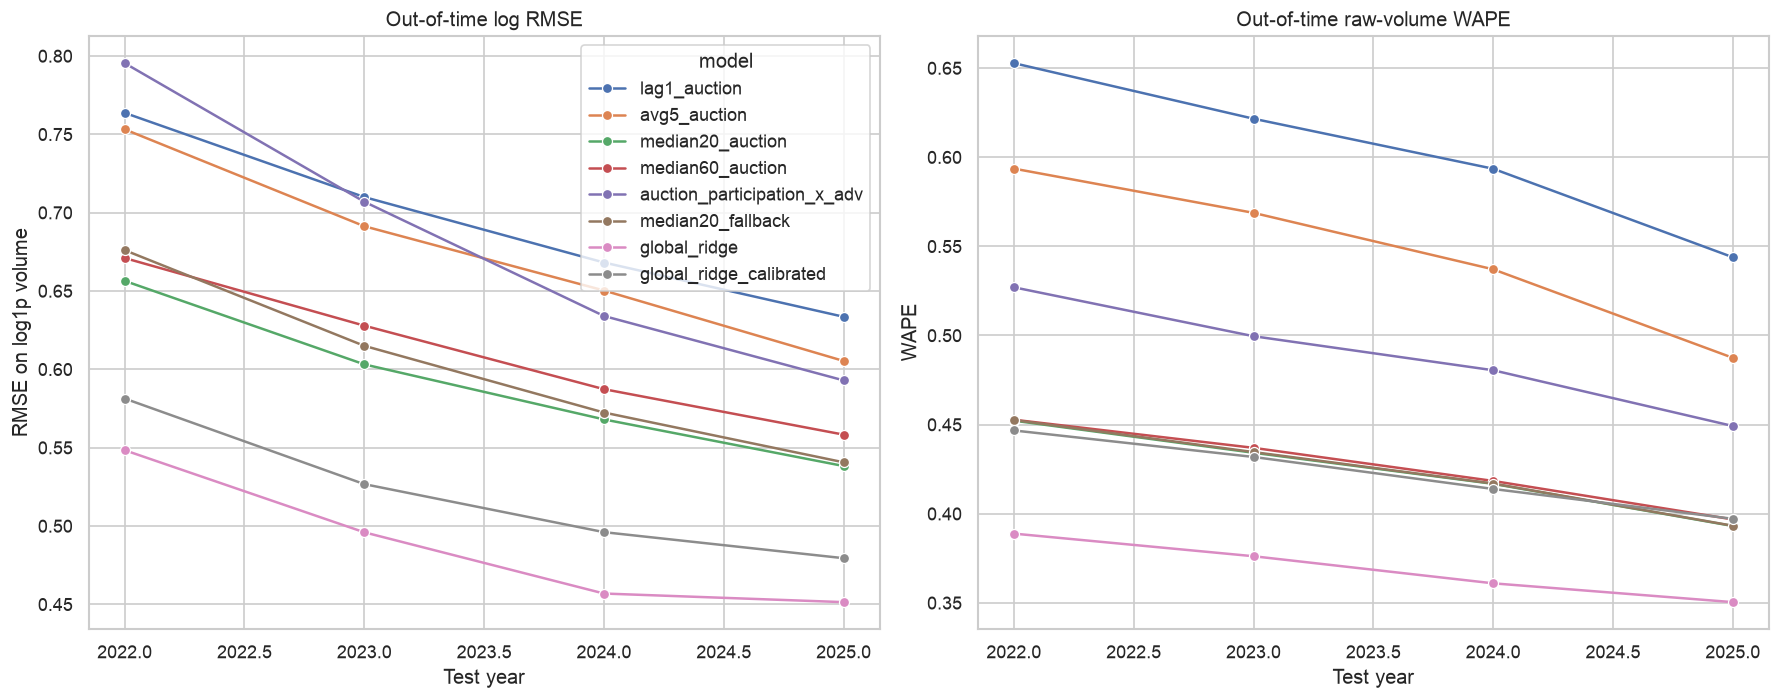

In [6]:
aggregate_metrics = overall_metrics.groupby("model").apply(
    lambda g: pd.Series({
        "mean_annual_coverage": g["coverage"].mean(),
        "mean_annual_mae_raw": g["mae_raw"].mean(),
        "mean_annual_wape": g["wape"].mean(),
        "mean_annual_mae_log": g["mae_log"].mean(),
        "mean_annual_rmse_log": g["rmse_log"].mean(),
        "mean_annual_spearman": g["spearman"].mean(),
        "mean_annual_bias": g["aggregate_bias"].mean(),
    }), include_groups=False
).reset_index().sort_values("mean_annual_rmse_log")
aggregate_metrics.to_csv(OUT / "aggregate_baseline_metrics.csv", index=False)
display(aggregate_metrics)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.lineplot(data=overall_metrics, x="test_year", y="rmse_log", hue="model", marker="o", ax=axes[0])
axes[0].set(title="Out-of-time log RMSE", xlabel="Test year", ylabel="RMSE on log1p volume")
sns.lineplot(data=overall_metrics, x="test_year", y="wape", hue="model", marker="o", ax=axes[1], legend=False)
axes[1].set(title="Out-of-time raw-volume WAPE", xlabel="Test year", ylabel="WAPE")
fig.tight_layout()
fig.savefig(OUT / "baseline_performance_by_year.png", bbox_inches="tight")
plt.show()

## Performance across candidate bifurcations

This section is diagnostic. It asks where the global ridge and historical reference succeed or fail; it does not yet fit separate models. Large, persistent differences across segments motivate the next global-versus-segmented experiment.

,dimension,segment,model,years,observations,mean_wape,mean_rmse_log,mean_spearman,mean_bias
0,auction_intensity_segment,high,global_ridge,4,399067,0.3600,0.4634,0.9505,-0.1366
1,auction_intensity_segment,high,global_ridge_calibrated,4,399067,0.4112,0.4939,0.9505,0.0453
2,auction_intensity_segment,high,median20_fallback,4,399067,0.4238,0.6165,0.9208,-0.2748
3,auction_intensity_segment,low,global_ridge,4,433572,0.4042,0.5718,0.9606,-0.1557
4,auction_intensity_segment,low,global_ridge_calibrated,4,433572,0.4579,0.6015,0.9606,0.0220
5,auction_intensity_segment,low,median20_fallback,4,433572,0.4532,0.6565,0.9436,-0.2257
6,auction_intensity_segment,mid,global_ridge,4,438739,0.3464,0.4152,0.9532,-0.1182
7,auction_intensity_segment,mid,global_ridge_calibrated,4,438739,0.4012,0.4551,0.9532,0.0676
8,auction_intensity_segment,mid,median20_fallback,4,438739,0.3996,0.5253,0.9275,-0.2117
9,event_segment,early_close,global_ridge,4,8742,0.3302,0.4559,0.9591,0.0212


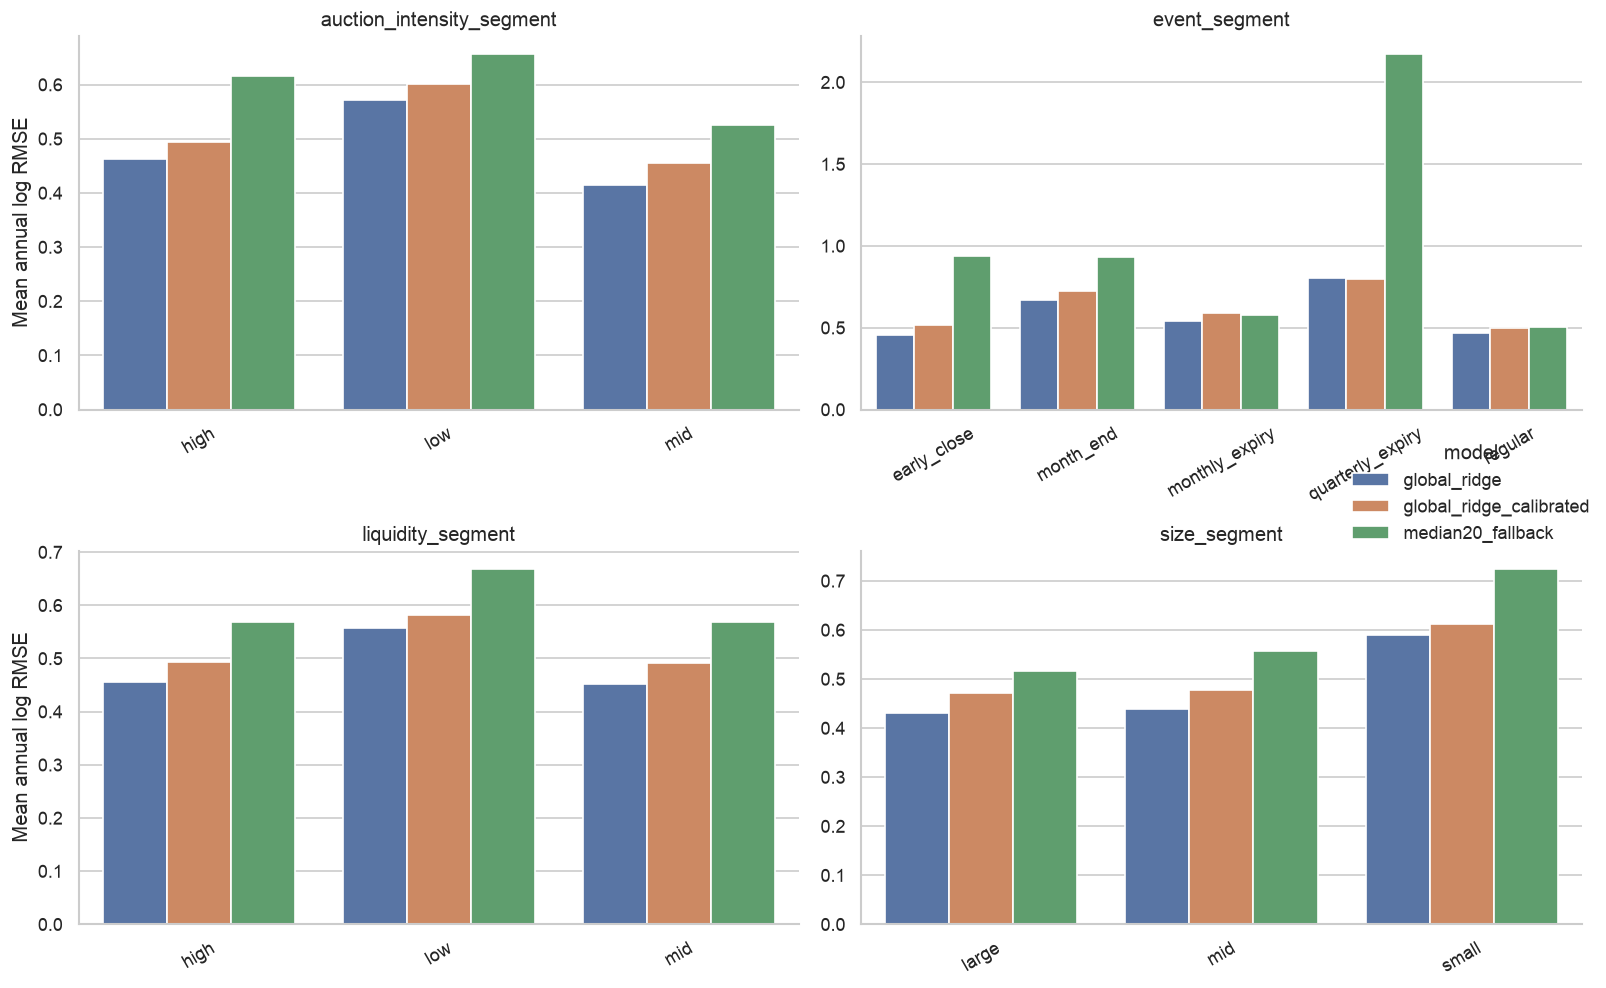

In [7]:
segment_summary = segment_metrics.groupby(["dimension", "segment", "model"]).agg(
    years=("test_year", "nunique"),
    observations=("observations", "sum"),
    mean_wape=("wape", "mean"),
    mean_rmse_log=("rmse_log", "mean"),
    mean_spearman=("spearman", "mean"),
    mean_bias=("aggregate_bias", "mean"),
).reset_index()
segment_summary.to_csv(OUT / "segment_performance_summary.csv", index=False)
display(segment_summary)

plot_segments = segment_summary[segment_summary["dimension"].isin([
    "size_segment", "liquidity_segment", "auction_intensity_segment", "event_segment"
])]
g = sns.catplot(
    data=plot_segments, x="segment", y="mean_rmse_log", hue="model",
    col="dimension", kind="bar", col_wrap=2, sharex=False, sharey=False,
    height=4.2, aspect=1.35,
)
g.set_titles("{col_name}")
g.set_axis_labels("", "Mean annual log RMSE")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)
g.figure.tight_layout()
g.figure.savefig(OUT / "performance_by_candidate_segment.png", bbox_inches="tight")
plt.show()

## Paired date-block uncertainty for the global ridge

The comparison below pairs both ridge variants against the deployable `median20_fallback` on identical stock-days. Resampling whole dates preserves same-day cross-sectional dependence better than treating millions of rows as independent. Negative differences favor the ridge variant.

In [8]:
daily_parts = []
for test_year in TEST_YEARS:
    path = PREDICTIONS / f"out_of_time_predictions_{test_year}.parquet"
    daily_parts.append(sql(f"""
        SELECT date,
               avg(abs(ln(1 + global_ridge) - log1p_auction_volume)
                   - abs(ln(1 + median20_fallback) - log1p_auction_volume)) AS log_mae_difference,
               sum(abs(global_ridge - auction_volume)) / sum(auction_volume)
                   - sum(abs(median20_fallback - auction_volume)) / sum(auction_volume)
                   AS daily_wape_difference,
               avg(abs(ln(1 + global_ridge_calibrated) - log1p_auction_volume)
                   - abs(ln(1 + median20_fallback) - log1p_auction_volume))
                   AS calibrated_log_mae_difference,
               sum(abs(global_ridge_calibrated - auction_volume)) / sum(auction_volume)
                   - sum(abs(median20_fallback - auction_volume)) / sum(auction_volume)
                   AS calibrated_daily_wape_difference
        FROM read_parquet('{path}')
        GROUP BY date
    """))
daily_differences = pd.concat(daily_parts, ignore_index=True)

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_rows = []
for metric in [
    "log_mae_difference", "daily_wape_difference",
    "calibrated_log_mae_difference", "calibrated_daily_wape_difference",
]:
    values = daily_differences[metric].dropna().to_numpy()
    draws = np.empty(3000)
    for i in range(len(draws)):
        draws[i] = rng.choice(values, size=len(values), replace=True).mean()
    bootstrap_rows.append({
        "metric": metric,
        "ridge_minus_reference_mean": values.mean(),
        "ci_2_5": np.quantile(draws, 0.025),
        "ci_97_5": np.quantile(draws, 0.975),
        "dates": len(values),
    })
bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT / "ridge_vs_median20_date_block_bootstrap.csv", index=False)
display(bootstrap)

,metric,ridge_minus_reference_mean,ci_2_5,ci_97_5,dates
0,log_mae_difference,-0.0551,-0.0679,-0.0437,1003
1,daily_wape_difference,-0.0248,-0.0320,-0.0184,1003
2,calibrated_log_mae_difference,-0.0034,-0.0169,0.0092,1003
3,calibrated_daily_wape_difference,0.0417,0.0337,0.0495,1003


## Handoff

This notebook freezes the first fair evaluation protocol. Later model comparisons should reuse the same out-of-time years, universe, metrics, and segment labels. Hyperparameter selection for more flexible models should occur strictly inside each historical training window.

In [9]:
artifact_manifest = pd.DataFrame({
    "artifact": [
        "Overall fold metrics", "Aggregate metrics", "Segment fold metrics",
        "Segment summary", "Date-block bootstrap", "Ridge coefficients",
        "Preprocessing manifest", "Out-of-time prediction directory",
    ],
    "path": [
        str(OUT / "overall_baseline_metrics.csv"),
        str(OUT / "aggregate_baseline_metrics.csv"),
        str(OUT / "segment_baseline_metrics.csv"),
        str(OUT / "segment_performance_summary.csv"),
        str(OUT / "ridge_vs_median20_date_block_bootstrap.csv"),
        str(OUT / "ridge_coefficients_by_fold.csv"),
        str(OUT / "preprocessing_manifest.json"),
        str(PREDICTIONS),
    ],
})
artifact_manifest.to_csv(OUT / "artifact_manifest.csv", index=False)
display(artifact_manifest)

,artifact,path
0,Overall fold metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Aggregate metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Segment fold metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Segment summary,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,Date-block bootstrap,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
5,Ridge coefficients,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
6,Preprocessing manifest,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
7,Out-of-time prediction directory,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
